# Week 3: excercise 2
### Excercise 2.1: Zero-crossing rate, upper and lower treshold

[Text(0.5, 0, 'Interval end time [s]'),
 Text(0.5, 1.0, 'Cumulative Zero Crossings over 10ms Intervals'),
 Text(0, 0.5, 'Number of zero crossings')]

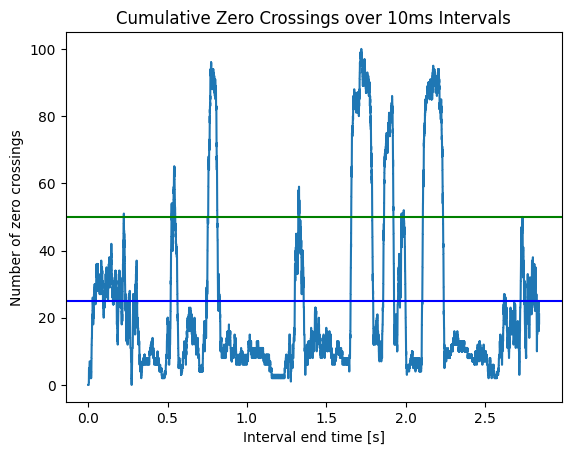

In [4]:
from typing import NamedTuple, Optional
import librosa


import numpy as np
from matplotlib.axes import Axes
from matplotlib.figure import Figure
from matplotlib import pyplot
from matplotlib.figure import Figure

import soundfile   # general audio file IO
import sounddevice   # audio data playback


#Using the script written last week:
(sample, sample_rate)=librosa.load("13ZZ637A.wav", sr=None)

sample_count=len(sample)

def compute_zero_crossing(samples: np.ndarray) -> np.ndarray:

    sample_count=len(sample)
    zero_crossing=np.zeros(sample_count)
    for i in range(1,sample_count):
        if (0 != np.sign(sample[i-1]) != np.sign(sample[i])): #checks if signs are different
            zero_crossing[i]=1
    return zero_crossing


def compute_zero_crossing_rates(zero_crossings: np.ndarray,interval_length: int):
    
    zero_crossing_intervals = np.ones(interval_length)
    result = np.convolve(zero_crossings, zero_crossing_intervals)
    return result[:len(zero_crossings)]


#Above this threshold the segment is assumed to be unvoiced
voiced_upper_limit = 50
#Below this threshold the segment is assumed to be voiced
unvoiced_lower_limit = 25

sample_count_10ms=int(0.01*sample_rate)
zero_crossings = compute_zero_crossing(sample)
zero_crossing_rates = compute_zero_crossing_rates(zero_crossings, interval_length=sample_count_10ms)

time_start=0
time_end=sample_count/sample_rate
time = np.linspace(time_start, time_end, sample_count)


diagram: Axes=pyplot.axes()
diagram.plot(time, zero_crossing_rates)
diagram.axhline(voiced_upper_limit, color="g"); diagram.axhline(unvoiced_lower_limit, color="b")
diagram.set(xlabel="Interval end time [s]", title="Cumulative Zero Crossings over 10ms Intervals", ylabel="Number of zero crossings")

### Excercise 2.2: Find and split the voiced and unvoiced segments

In [7]:
split_locations=[]

is_voiced: bool = zero_crossing_rates[0] < unvoiced_lower_limit
is_in_voiced_segment = True


for i in range(1, len(zero_crossing_rates)):
    zero_crossing_rate = zero_crossing_rates[i]
    
    if is_in_voiced_segment:
        is_voiced_transition = is_voiced > (is_voiced := zero_crossing_rate < unvoiced_lower_limit)
        if is_voiced_transition:
            last_transition = i
        
        if zero_crossing_rate > voiced_upper_limit:
            split_locations.append(last_transition)
            is_in_voiced_segment = False
    
    else:
        is_voiced_transition = is_voiced < (is_voiced := zero_crossing_rate < unvoiced_lower_limit)
        if is_voiced_transition:
            split_locations.append(i)
            is_in_voiced_segment = True


segments=np.split(sample, split_locations)

unvoiced_indice=split_locations[::2]
unvoiced_segments=segments[1::2]

voiced_indices = [0, *split_locations[1::2]]
voiced_segments = segments[::2]


#Visualization of segment separation

for t in time[unvoiced_indice]:
	diagram.axvline(t, color="k")

for t in time[voiced_indices]:
	diagram.axvline(t, color="r")

pyplot.show()

### Excercise 2.3: Create wav-files and play the segments


In [11]:
voiced_wav=np.concatenate(voiced_segments); unvoiced_wav=np.concatenate(unvoiced_segments)

soundfile.write('voiced_segments.wav', voiced_wav, sample_rate)
soundfile.write('unvoiced_segments.wav', unvoiced_wav, sample_rate)


for samples in [sample, voiced_wav, unvoiced_wav]:
	sounddevice.play(samples, sample_rate)
	sounddevice.wait()